# 01 · Inside the Images — Cleaning, Pixels and Singular Values

**Project:** SVD-based digital watermarking & steganography (course 01076020)

**What this notebook answers:** *Is the data fit for the method, and what does the method need to know about it?*
Notebook 00 only described the files. Here we look at the **pixel values** and at the **singular values (SVD)** of the images.

| Step | Question | Why the report needs it |
|---|---|---|
| 1 | Are any images unusable (broken, duplicated, blank)? | Data cleaning, before/after table |
| 2 | How do we make all images fit the method? | Standardisation (grayscale + crop to multiples of 8) |
| 3 | What does an image look like as a matrix? | Vector/matrix representation of the data |
| 4 | How bright / contrasty are the images? | Data statistics; risk of pixel clipping |
| 5 | How is an image's energy spread over singular values? | Evidence for the SVD theory |
| 6 | How big are singular values inside 8×8 blocks? | Choosing the QIM step size Δ |

**Reading guide.** Each section begins with *what* and *why*, then the code and output, then a **Takeaway** computed from the numbers above it.

### Glossary

| Term | Meaning |
|---|---|
| **Pixel** | One dot of an image. In a grayscale image it is a number from 0 (black) to 255 (white). |
| **Grayscale image as a matrix** | A table of pixel numbers: one row per image row, one column per image column. |
| **Brightness** | The *average* pixel value of an image. Low = dark picture, high = bright picture. |
| **Contrast (std)** | The *standard deviation* of pixel values: how much pixels differ from each other. 0 means every pixel is identical. |
| **Flat image** | An image with almost no detail (all one colour, or very faint changes): contrast below a small threshold. |
| **Duplicate** | An image with exactly the same pixels as another one. |
| **Crop** | Cutting away a thin border so the size becomes a multiple of 8. |
| **Singular values σ₁ ≥ σ₂ ≥ …** | Numbers produced by SVD; σ₁ is the "strongest" component of the matrix, later ones are finer detail. |
| **Energy** | Σσᵢ² (the sum of squared pixel values of the matrix). "Energy held by σ₁" = σ₁² divided by that sum. |
| **Rank k** | Using only the first k singular values to rebuild the image. |
| **Block** | An 8×8 square of pixels. Steganography hides one bit per block. |
| **QIM and Δ (step size)** | Quantisation Index Modulation: a singular value σ is moved to the nearest multiple of Δ whose index is even (bit 0) or odd (bit 1). σ changes by at most Δ. |
| **Clipping / saturation** | Pixel values cannot leave 0…255. A pixel already at 255 that should become 258 is cut back to 255, which loses information. |


> **Note.** This EDA was written before the final method was fixed. The QIM description in the glossary above is the early *rounding* form
> (move σ to the nearest mark). The final implementation (`src/svdmark/stego.py`) uses the *interval-parity* form (the same idea with the marks shifted by Δ/2) —
> interval q = floor(σ/Δ), bit = q mod 2, σ moved to the centre of the nearest interval with the right parity — so that a drift of up to Δ/2 is tolerated.
> The data findings here (sizes, cleaning, pixel and singular-value statistics) are unaffected.

In [1]:
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, GRAY, ACCENT = "#2f6db5", "#6b7280", "#c2410c"
pd.options.display.float_format = "{:,.1f}".format

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "images"
meta = pd.read_csv(ROOT / "results" / "dataset_stats.csv")

# Parameters of this notebook (our own choices, stated so they can be questioned)
BLOCK = 8        # block side used by the steganography method
FLAT_STD = 10    # an image with contrast (std) below this counts as "flat"
MIN_SIDE = 64    # an image with a side shorter than this has too few blocks
print(f"{len(meta)} images listed in results/dataset_stats.csv")

500 images listed in results/dataset_stats.csv


## 1. Load the images and clean the data

**What.** Every image is opened and converted to **grayscale** (luma formula: 0.299·R + 0.587·G + 0.114·B).
Then four checks decide whether it is usable.

| Check | What it catches | Rule used here |
|---|---|---|
| Unreadable | broken or truncated file | the file cannot be opened |
| Duplicate | the same picture twice (would inflate results) | identical pixels (same MD5 fingerprint) as an earlier image |
| Flat | almost no detail; SVD has nothing to hide data in | contrast (std) < 10 |
| Too small | too few 8×8 blocks to carry data | a side shorter than 64 px |

The thresholds 10 and 64 are our own choices, not a standard.

In [2]:
records, gray = [], {}
for r in meta.itertuples(index=False):
    rec = {"split": r.split, "filename": r.filename}
    try:
        with Image.open(DATA / r.split / r.filename) as im:
            im.load()
            g = np.asarray(im.convert("L"), dtype=np.float64)
        rec.update(readable=True, height=g.shape[0], width=g.shape[1],
                   brightness_mean=g.mean(), contrast_std=g.std(),
                   darkest_px=g.min(), brightest_px=g.max(),
                   pixel_hash=hashlib.md5(g.astype(np.uint8).tobytes()).hexdigest())
        gray[(r.split, r.filename)] = g
    except Exception:
        rec.update(readable=False)
    records.append(rec)
df = pd.DataFrame(records)

df["is_duplicate"] = df["readable"] & df.duplicated("pixel_hash", keep="first")
df["is_flat"] = df["readable"] & (df["contrast_std"] < FLAT_STD)
df["is_too_small"] = df["readable"] & ((df["height"] < MIN_SIDE) | (df["width"] < MIN_SIDE))
df["needs_crop"] = df["readable"] & ((df["height"] % BLOCK != 0) | (df["width"] % BLOCK != 0))
df["discard"] = ~df["readable"] | df["is_duplicate"] | df["is_flat"] | df["is_too_small"]
df["status"] = np.select([df["discard"], df["needs_crop"]], ["Discarded", "Usable after cropping"], default="Ready as-is")

N = len(df)
checks = pd.DataFrame({
    "What it catches": ["Broken / truncated file", "Same pixels as an earlier image", f"Almost no detail (contrast < {FLAT_STD})", f"A side shorter than {MIN_SIDE} px"],
    "Images flagged": [int((~df["readable"]).sum()), int(df["is_duplicate"].sum()), int(df["is_flat"].sum()), int(df["is_too_small"].sum())]},
    index=["Unreadable", "Duplicate", "Flat", "Too small"])
checks["% of images"] = checks["Images flagged"] / N * 100
display(Markdown("**Result of each check**"))
display(checks)

order = ["Ready as-is", "Usable after cropping", "Discarded"]
status_tbl = df["status"].value_counts().reindex(order, fill_value=0).to_frame("Images")
status_tbl["% of images"] = status_tbl["Images"] / N * 100
status_tbl.index.name = "Status of each image"
display(Markdown("**Status of each image**"))
display(status_tbl)

kept = int((~df["discard"]).sum())
ba = pd.DataFrame({"Images": [N, kept], "% of the original": [100.0, kept / N * 100]}, index=["Before cleaning", "After cleaning"])
display(Markdown("**Before vs. after cleaning**"))
display(ba)

closest = df.loc[df["contrast_std"].idxmin()]
print(f"Closest call: image {closest['filename']} has contrast {closest['contrast_std']:.1f} (the 'flat' threshold is {FLAT_STD}); it is kept.")

**Result of each check**

,What it catches,Images flagged,% of images
Unreadable,Broken / truncated file,0,0.0
Duplicate,Same pixels as an earlier image,0,0.0
Flat,Almost no detail (contrast < 10),0,0.0
Too small,A side shorter than 64 px,0,0.0


**Status of each image**

,Images,% of images
Status of each image,,
Ready as-is,0,0.0
Usable after cropping,500,100.0
Discarded,0,0.0


**Before vs. after cleaning**

,Images,% of the original
Before cleaning,500,100.0
After cleaning,500,100.0


Closest call: image 80099.jpg has contrast 12.1 (the 'flat' threshold is 10); it is kept.


In [3]:
display(Markdown(f"""**Takeaway.** {kept} of {N} images ({kept/N*100:.0f}%) pass all four checks; {N-kept} were discarded.
BSDS500 is a curated benchmark, so almost no cleaning is needed. The one thing every image needs is a **crop**
({int(df['needs_crop'].sum())} of {N} have a side that is not a multiple of {BLOCK}). The report can say this honestly:
*the dataset is already clean; preprocessing = grayscale conversion + crop.*"""))

**Takeaway.** 500 of 500 images (100%) pass all four checks; 0 were discarded.
BSDS500 is a curated benchmark, so almost no cleaning is needed. The one thing every image needs is a **crop**
(500 of 500 have a side that is not a multiple of 8). The report can say this honestly:
*the dataset is already clean; preprocessing = grayscale conversion + crop.*

## 2. Standardise: grayscale and crop to multiples of 8

**What.** The method cuts an image into 8×8 blocks, so width and height must be multiples of 8.
Each image is **center-cropped**: the thin leftover border is removed equally from both sides.

**Why crop and not resize?** Resizing recomputes the pixel values, which would mix the effect of resizing with the effect of embedding.
Cropping keeps every remaining pixel exactly as it was.

In [4]:
def preprocess(g, b=BLOCK):
    h, w = g.shape
    H, W = h // b * b, w // b * b           # largest multiples of b that fit
    top, left = (h - H) // 2, (w - W) // 2  # split the leftover evenly
    return g[top:top + H, left:left + W]

keep_keys = [(r["split"], r["filename"]) for _, r in df[~df["discard"]].iterrows()]
imgs = {k: preprocess(gray[k]) for k in keep_keys}

conv = pd.DataFrame([{"Original size (w × h px)": f"{gray[k].shape[1]} × {gray[k].shape[0]}",
                      "After crop (w × h px)": f"{a.shape[1]} × {a.shape[0]}",
                      "Pixels removed (width, height)": f"{gray[k].shape[1]-a.shape[1]}, {gray[k].shape[0]-a.shape[0]}"}
                     for k, a in imgs.items()]).value_counts().reset_index(name="Images")
display(conv)
print(f"{len(imgs)} images are now grayscale matrices whose sides are multiples of {BLOCK}.")

,Original size (w × h px),After crop (w × h px),"Pixels removed (width, height)",Images
0,481 × 321,480 × 320,"1, 1",348
1,321 × 481,320 × 480,"1, 1",152


500 images are now grayscale matrices whose sides are multiples of 8.


In [5]:
lost = np.mean([1 - a.size / gray[k].size for k, a in imgs.items()]) * 100
display(Markdown(f"""**Takeaway.** Cropping may remove up to {BLOCK-1} pixels per direction; here it removed {int(max(gray[k].shape[1]-a.shape[1] for k, a in imgs.items()))} px, which is on average
**{lost:.1f}%** of an image's pixels. After this step the dataset has {conv.shape[0]} distinct matrix shapes
(landscape and portrait versions of the same size), so a block grid fits every image exactly."""))

**Takeaway.** Cropping may remove up to 7 pixels per direction; here it removed 1 px, which is on average
**0.5%** of an image's pixels. After this step the dataset has 2 distinct matrix shapes
(landscape and portrait versions of the same size), so a block grid fits every image exactly.

## 3. One image as a matrix

**What.** This is the *vector/matrix representation of the data* that the report requires.
A grayscale image with 320 rows and 480 columns is a **320 × 480 matrix A**; the number in row *i*, column *j* is the brightness of that pixel.

**How to read the figure.** Left: the whole image, with a red square marking one 8×8 block.
Right: the 64 numbers inside that block. SVD will later be applied to exactly such 8×8 matrices.

Image 100075.jpg: A is a 320 × 480 matrix (320 rows × 480 columns), values from 18 to 254.


**Top-left 6 × 6 corner of A** (each number = one pixel, 0 = black, 255 = white)

,col 0,col 1,col 2,col 3,col 4,col 5
row 0,111,115,116,119,126,131
row 1,108,109,110,116,130,139
row 2,118,116,117,123,133,137
row 3,123,122,126,133,134,131
row 4,125,126,132,138,137,134
row 5,136,136,139,141,142,143


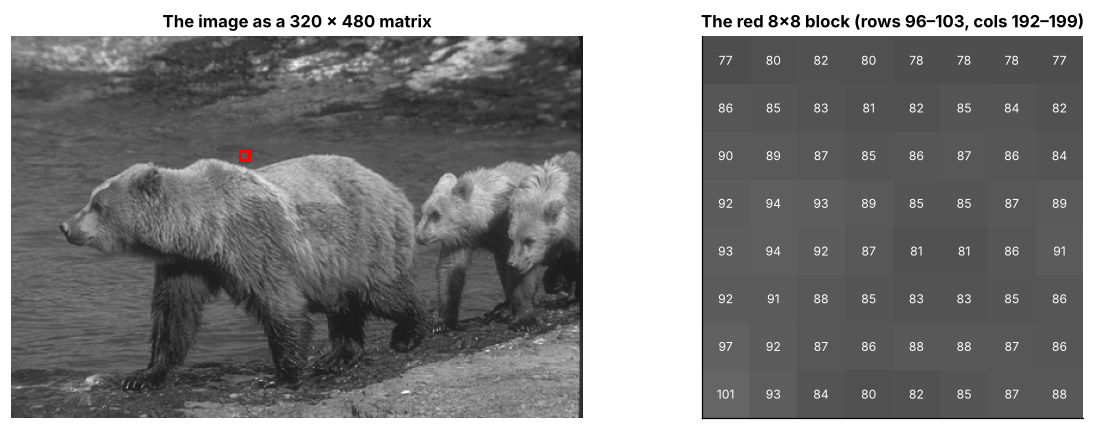

In [6]:
key = keep_keys[0]
A = imgs[key]
r0, c0 = 96, 192
print(f"Image {key[1]}: A is a {A.shape[0]} × {A.shape[1]} matrix ({A.shape[0]} rows × {A.shape[1]} columns), values from {A.min():.0f} to {A.max():.0f}.")
display(Markdown("**Top-left 6 × 6 corner of A** (each number = one pixel, 0 = black, 255 = white)"))
display(pd.DataFrame(A[:6, :6].astype(int), index=[f"row {i}" for i in range(6)], columns=[f"col {j}" for j in range(6)]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].imshow(A, cmap="gray", vmin=0, vmax=255); ax[0].grid(False); ax[0].axis("off")
ax[0].add_patch(plt.Rectangle((c0 - .5, r0 - .5), BLOCK, BLOCK, fill=False, ec="red", lw=2))
ax[0].set_title(f"The image as a {A.shape[0]} × {A.shape[1]} matrix")
blk = A[r0:r0 + BLOCK, c0:c0 + BLOCK]
ax[1].imshow(blk, cmap="gray", vmin=0, vmax=255); ax[1].grid(False)
for i in range(BLOCK):
    for j in range(BLOCK):
        ax[1].text(j, i, f"{blk[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if blk[i, j] < 128 else "black")
ax[1].set_title(f"The red 8×8 block (rows {r0}–{r0+7}, cols {c0}–{c0+7})")
ax[1].set_xticks([]); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

## 4. Pixel statistics

**What.** For each image we compute four numbers from its pixels: **brightness** (average pixel value), **contrast** (standard deviation),
the **darkest pixel** and the **brightest pixel**. Then we summarise those four numbers over all images.

**How to read the table.** Each *row* is a measurement made **per image**. The three *columns* summarise it **across all images**:
the average image, the image with the highest value, the image with the lowest value.
For example, in the row "Brightness", the column "Lowest" is the *darkest picture of the whole dataset*.

In [7]:
clean = df[~df["discard"]].copy()
measures = {"Brightness (average pixel value)": "brightness_mean",
            "Contrast (std of pixel values)": "contrast_std",
            "Darkest pixel (0 = black)": "darkest_px",
            "Brightest pixel (255 = white)": "brightest_px"}
stat_tbl = pd.DataFrame([[clean[c].mean(), clean[c].max(), clean[c].min()] for c in measures.values()],
                        index=list(measures), columns=["Average across images", "Highest image", "Lowest image"])
stat_tbl.index.name = "Measured per image"
display(stat_tbl)

b = stat_tbl.loc["Brightness (average pixel value)"]
print(f"Example: the average image has brightness {b.iloc[0]:.0f} of 255; the brightest picture averages {b.iloc[1]:.0f}, the darkest {b.iloc[2]:.0f}.")

,Average across images,Highest image,Lowest image
Measured per image,,,
Brightness (average pixel value),109.0,212.1,33.5
Contrast (std of pixel values),50.7,114.1,12.1
Darkest pixel (0 = black),11.7,55.0,0.0
Brightest pixel (255 = white),250.2,255.0,166.0


Example: the average image has brightness 109 of 255; the brightest picture averages 212, the darkest 33.


**What the extreme images look like** (so the numbers above can be checked by eye):

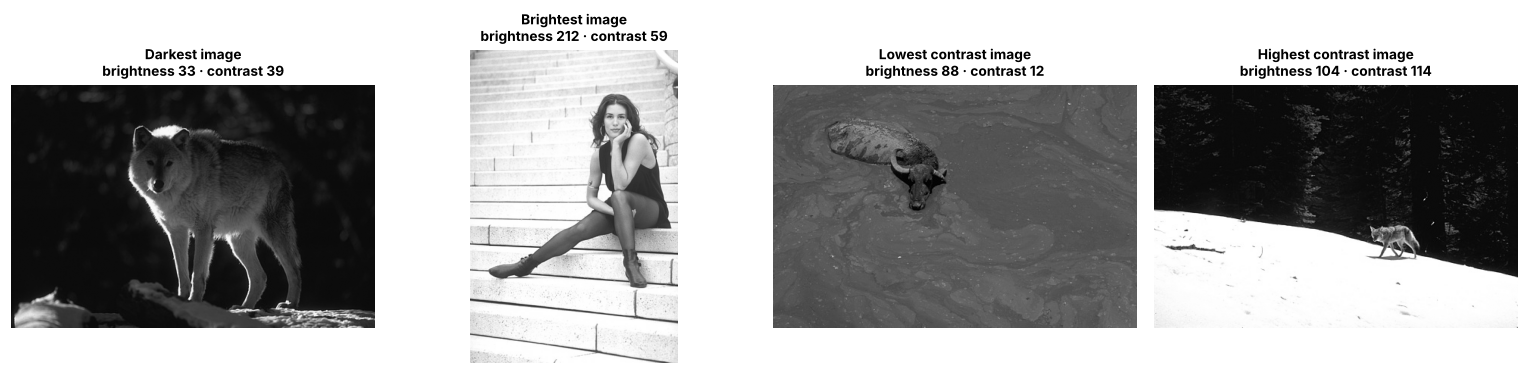

In [8]:
picks = {"Darkest": clean["brightness_mean"].idxmin(), "Brightest": clean["brightness_mean"].idxmax(),
         "Lowest contrast": clean["contrast_std"].idxmin(), "Highest contrast": clean["contrast_std"].idxmax()}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (title, i) in zip(axes, picks.items()):
    row = clean.loc[i]
    ax.imshow(gray[(row["split"], row["filename"])], cmap="gray", vmin=0, vmax=255); ax.axis("off"); ax.grid(False)
    ax.set_title(f"{title} image\nbrightness {row['brightness_mean']:.0f} · contrast {row['contrast_std']:.0f}", fontsize=9)
plt.tight_layout(); plt.show()

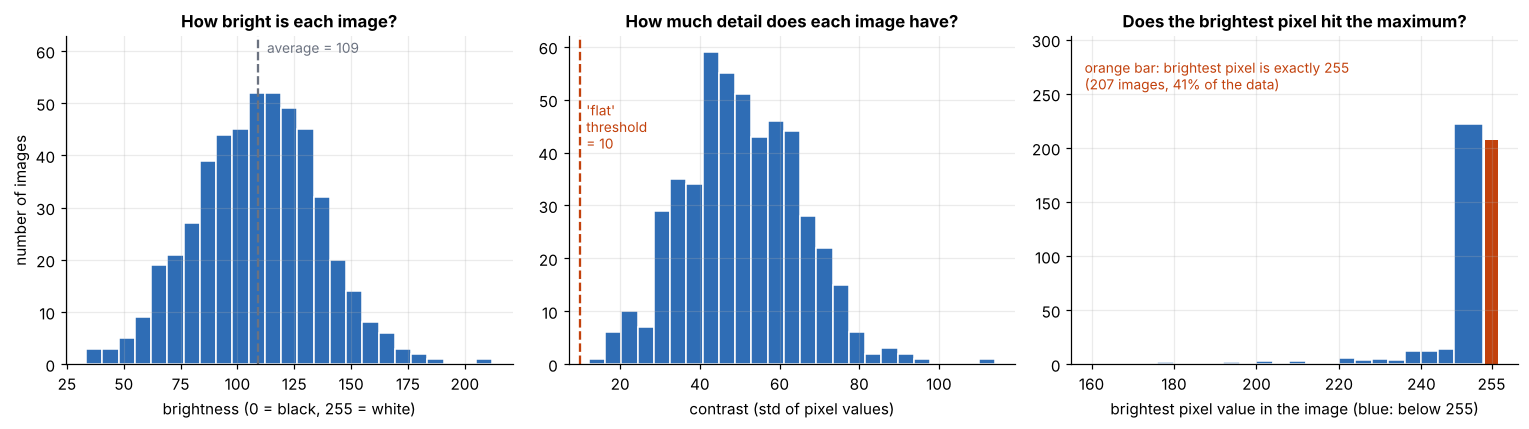

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(clean["brightness_mean"], bins=25, color=BLUE, edgecolor="white")
ax[0].axvline(clean["brightness_mean"].mean(), color=GRAY, ls="--")
ax[0].set_ylim(0, ax[0].get_ylim()[1] * 1.15)
ax[0].text(clean["brightness_mean"].mean() + 4, ax[0].get_ylim()[1] * 0.95, f"average = {clean['brightness_mean'].mean():.0f}", color=GRAY, fontsize=9)
ax[0].set_title("How bright is each image?"); ax[0].set_xlabel("brightness (0 = black, 255 = white)"); ax[0].set_ylabel("number of images")
ax[1].hist(clean["contrast_std"], bins=25, color=BLUE, edgecolor="white")
ax[1].axvline(FLAT_STD, color=ACCENT, ls="--"); ax[1].text(FLAT_STD + 1.5, ax[1].get_ylim()[1] * 0.80, f"'flat'\nthreshold\n= {FLAT_STD}", color=ACCENT, fontsize=9, va="top")
ax[1].set_title("How much detail does each image have?"); ax[1].set_xlabel("contrast (std of pixel values)")
bp = clean["brightest_px"]
n255 = int((bp == 255).sum())
ax[2].hist(bp[bp < 255], bins=np.append(np.arange(160, 252, 4), 255), color=BLUE, edgecolor="white")
ax[2].bar(257, n255, width=3, color=ACCENT)
ax[2].text(0.03, 0.93, f"orange bar: brightest pixel is exactly 255\n({n255} images, {n255/len(bp)*100:.0f}% of the data)", transform=ax[2].transAxes, fontsize=9, color=ACCENT, va="top")
ax[2].set_xticks([160, 180, 200, 220, 240, 257]); ax[2].set_xticklabels(["160", "180", "200", "220", "240", "255"])
ax[2].set_ylim(0, ax[2].get_ylim()[1] * 1.3)
ax[2].set_title("Does the brightest pixel hit the maximum?"); ax[2].set_xlabel("brightest pixel value in the image (blue: below 255)")
plt.tight_layout(); plt.show()

### Clipping risk

Embedding changes pixel values slightly. A pixel already at **255** (or **0**) cannot go further, so the change is cut off (*clipped*)
and the embedded information is partly lost. Images with many pure-white or pure-black pixels are therefore riskier.

In [10]:
sat = pd.Series({k: float(((a == 0) | (a == 255)).mean() * 100) for k, a in imgs.items()})
clip_tbl = pd.DataFrame({"Images": [int((clean["brightest_px"] == 255).sum()), int((clean["darkest_px"] == 0).sum()),
                                   int((sat > 0).sum()), int((sat > 1).sum()), int((sat > 5).sum())]},
                        index=["Has at least one pure-white pixel (255)", "Has at least one pure-black pixel (0)",
                               "Has any pure-black or pure-white pixel", "…more than 1% of its pixels are pure black/white",
                               "…more than 5% of its pixels are pure black/white"])
clip_tbl["% of images"] = clip_tbl["Images"] / len(clean) * 100
display(clip_tbl)

,Images,% of images
Has at least one pure-white pixel (255),207,41.4
Has at least one pure-black pixel (0),76,15.2
Has any pure-black or pure-white pixel,241,48.2
…more than 1% of its pixels are pure black/white,44,8.8
…more than 5% of its pixels are pure black/white,19,3.8


In [11]:
display(Markdown(f"""**Takeaway.**
* A typical image has brightness {clean['brightness_mean'].mean():.0f}/255 and contrast {clean['contrast_std'].mean():.0f}: neither too dark nor featureless. The lowest contrast in the data is {clean['contrast_std'].min():.1f}, close to our 'flat' threshold of {FLAT_STD} but still above it.
* **{clip_tbl.iloc[0,0]} images ({clip_tbl.iloc[0,1]:.0f}%)** contain a pure-white pixel, but only **{clip_tbl.iloc[3,0]}** have more than 1% saturated pixels, so clipping should affect only a minority of images.
  When we later see unusually high bit-error rates for some images, check whether those are the saturated ones."""))

**Takeaway.**
* A typical image has brightness 109/255 and contrast 51: neither too dark nor featureless. The lowest contrast in the data is 12.1, close to our 'flat' threshold of 10 but still above it.
* **207 images (41%)** contain a pure-white pixel, but only **44** have more than 1% saturated pixels, so clipping should affect only a minority of images.
  When we later see unusually high bit-error rates for some images, check whether those are the saturated ones.

## 5. Singular values of whole images

**What.** SVD writes an image matrix A as a sum of layers: A = σ₁·u₁v₁ᵀ + σ₂·u₂v₂ᵀ + … The numbers σ₁ ≥ σ₂ ≥ … tell how much each layer contributes.
The **energy** Σσᵢ² is the total "size" of the image, so the share of the first k layers is

> energy at rank k = (σ₁² + … + σₖ²) / (σ₁² + … + σᵣ²).

*Tiny example:* σ = [10, 3, 1] gives squares [100, 9, 1]; the first layer alone holds 100 / 110 = **91%** of the energy.

**Why the report needs it.** If a few σ carry nearly all the energy, then (a) an image can be compressed by keeping few layers, and
(b) the small later σ can be changed with little visible effect, which is what watermarking exploits.

In [12]:
def rank_for(s, p):
    """Smallest k whose first k singular values hold at least a fraction p of the energy."""
    return int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), p) + 1)

sv = {k: np.linalg.svd(a, compute_uv=False) for k, a in imgs.items()}
e1 = np.array([s[0] ** 2 / np.sum(s ** 2) * 100 for s in sv.values()])
kk = {p: np.array([rank_for(s, p / 100) for s in sv.values()]) for p in (90, 95, 99)}
full_rank = int(np.median([len(s) for s in sv.values()]))

rows = {"Energy held by σ₁ alone (%)": e1}
rows.update({f"Rank k needed to hold {p}% of the energy": v for p, v in kk.items()})
svd_tbl = pd.DataFrame({name: [v.mean(), np.median(v), v.max(), v.min()] for name, v in rows.items()},
                       index=["Average", "Median (typical)", "Highest image", "Lowest image"]).T
svd_tbl.index.name = "Measured per image"
display(Markdown(f"*(A full-rank image here has {full_rank} singular values.)*"))
display(svd_tbl)

*(A full-rank image here has 320 singular values.)*

,Average,Median (typical),Highest image,Lowest image
Measured per image,,,,
Energy held by σ₁ alone (%),88.9,90.1,99.8,59.6
Rank k needed to hold 90% of the energy,2.5,1.0,28.0,1.0
Rank k needed to hold 95% of the energy,7.0,4.0,62.0,1.0
Rank k needed to hold 99% of the energy,40.5,35.0,144.0,1.0


**How to read the charts.**
Left: each faint line is one image's singular values (log scale); a steep drop means few σ matter.
Middle: how much energy the first k singular values hold; the line is the typical image, the band covers 80% of images.
Right: how many singular values an image needs to reach 95% of its energy; each bar counts the images that need that many.

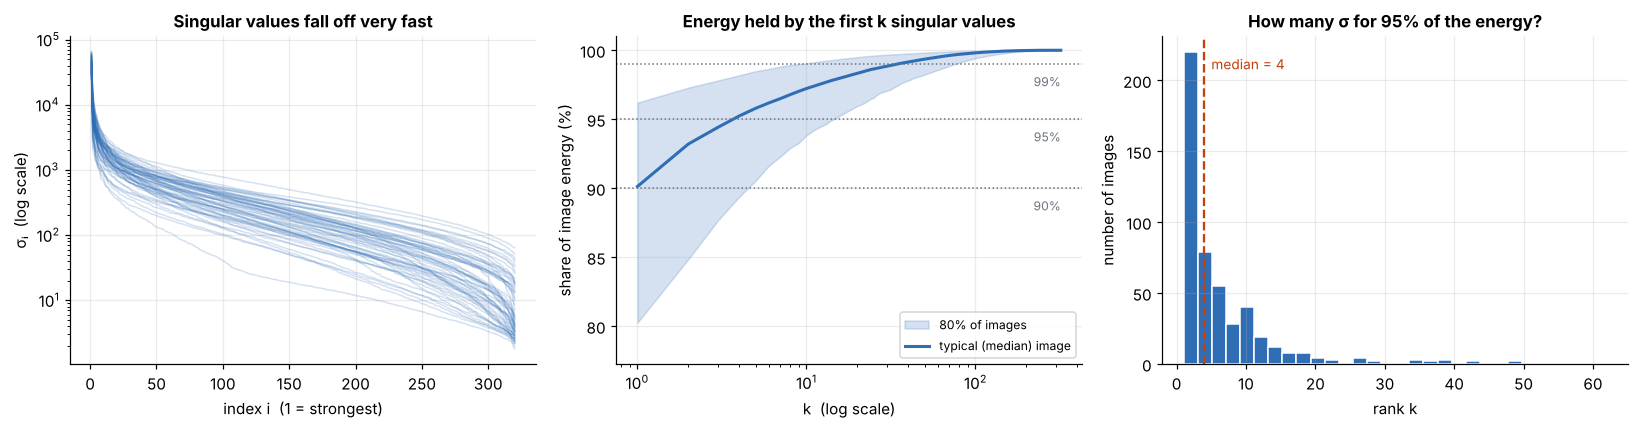

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for s in list(sv.values())[:60]:
    ax[0].semilogy(np.arange(1, len(s) + 1), s, color=BLUE, alpha=0.2, lw=1)
ax[0].set_title("Singular values fall off very fast"); ax[0].set_xlabel("index i  (1 = strongest)"); ax[0].set_ylabel("σᵢ  (log scale)")

L = min(len(s) for s in sv.values())
M = np.array([np.cumsum(s[:L] ** 2) / np.sum(s ** 2) for s in sv.values()]) * 100
kx = np.arange(1, L + 1)
lo, med, hi = np.percentile(M, [10, 50, 90], axis=0)
ax[1].fill_between(kx, lo, hi, color=BLUE, alpha=0.2, label="80% of images")
ax[1].plot(kx, med, color=BLUE, lw=2, label="typical (median) image")
for p in (90, 95, 99): ax[1].axhline(p, color=GRAY, ls=":", lw=1); ax[1].text(L, p - 1.6, f"{p}%", color=GRAY, fontsize=8, ha="right")
ax[1].set_xscale("log"); ax[1].set_ylim(max(0, lo.min() - 3), 101)
ax[1].set_title("Energy held by the first k singular values"); ax[1].set_xlabel("k  (log scale)"); ax[1].set_ylabel("share of image energy (%)"); ax[1].legend(loc="lower right", fontsize=8)

ax[2].hist(kk[95], bins=30, color=BLUE, edgecolor="white")
ax[2].axvline(np.median(kk[95]), color=ACCENT, ls="--"); ax[2].text(np.median(kk[95]) + 1, ax[2].get_ylim()[1] * 0.9, f"median = {np.median(kk[95]):.0f}", color=ACCENT, fontsize=9)
ax[2].set_title("How many σ for 95% of the energy?"); ax[2].set_xlabel("rank k"); ax[2].set_ylabel("number of images")
plt.tight_layout(); plt.show()

**Seeing it.** One typical image rebuilt from only its first *k* layers. If the energy argument is right, a handful of layers should already look recognisable.

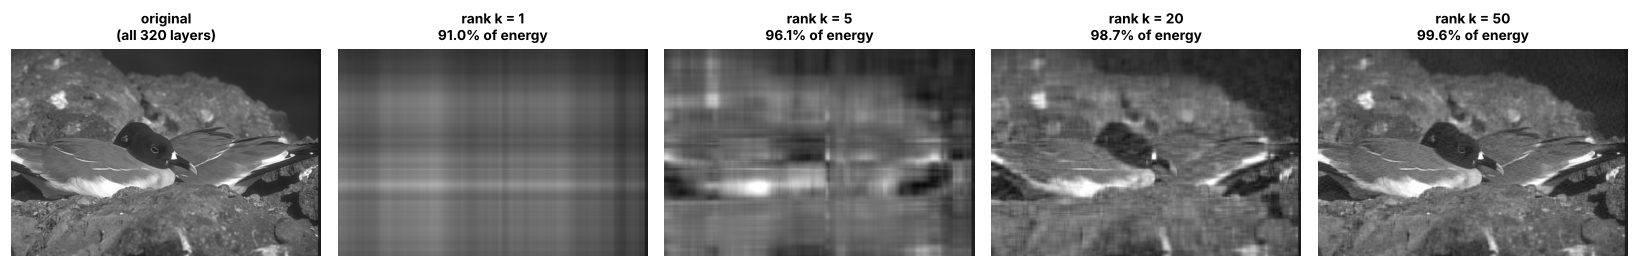

In [14]:
i_typ = int(np.argmin(np.abs(kk[95] - np.median(kk[95]))))
k_typ = keep_keys[i_typ]
U, s, Vt = np.linalg.svd(imgs[k_typ], full_matrices=False)
ks = [1, 5, 20, 50]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(imgs[k_typ], cmap="gray", vmin=0, vmax=255); axes[0].set_title(f"original\n(all {len(s)} layers)", fontsize=9)
for ax, k in zip(axes[1:], ks):
    R = (U[:, :k] * s[:k]) @ Vt[:k]
    ax.imshow(np.clip(R, 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rank k = {k}\n{np.sum(s[:k]**2)/np.sum(s**2)*100:.1f}% of energy", fontsize=9)
for ax in axes: ax.axis("off"); ax.grid(False)
plt.tight_layout(); plt.show()

In [15]:
display(Markdown(f"""**Takeaway.** The first singular value alone holds on average **{e1.mean():.0f}%** of an image's energy.
For the typical image, **{np.median(kk[95]):.0f}** layers out of {full_rank} are enough for 95% and **{np.median(kk[99]):.0f}** for 99%;
even the most detailed image needs only {kk[95].max()} for 95%. So image energy is strongly concentrated in the first few σ, which is
the first theory the report relies on. Note that "% of energy" is dominated by overall brightness; fine detail lives in the later σ. Which σ to hide data in is decided in the pilot experiment."""))

**Takeaway.** The first singular value alone holds on average **89%** of an image's energy.
For the typical image, **4** layers out of 320 are enough for 95% and **35** for 99%;
even the most detailed image needs only 62 for 95%. So image energy is strongly concentrated in the first few σ, which is
the first theory the report relies on. Note that "% of energy" is dominated by overall brightness; fine detail lives in the later σ. Which σ to hide data in is decided in the pilot experiment.

## 6. Singular values inside 8×8 blocks

**What.** The steganography part works on **8×8 blocks**: each block gets its own SVD (8 singular values σ₁…σ₈) and one σ is quantised to hide **one bit**.
So we need to know how large each σₖ typically is inside a block.

**Why it matters for Δ.** QIM moves σ to a multiple of Δ with the right parity, so σ changes by up to **Δ**. Because the matrices U and V are orthonormal,
a change of δ in one σ changes the 64 pixels of the block by about **δ / 8 gray levels (RMS)**. A larger Δ is more robust to attacks but more visible.
If σ is *smaller than Δ*, the change can be larger than σ itself, which is a problem.

In [16]:
def blocks_of(a, b=BLOCK):
    H, W = a.shape
    return a.reshape(H // b, b, W // b, b).swapaxes(1, 2).reshape(-1, b, b)

S = np.concatenate([np.linalg.svd(blocks_of(a), compute_uv=False) for a in imgs.values()])   # (n_blocks, 8)
print(f"{S.shape[0]:,} blocks of size {BLOCK}×{BLOCK} from {len(imgs)} images; each block has {S.shape[1]} singular values.")
print("Example (the red block of section 3): σ₁…σ₈ =", ", ".join(f"{v:.1f}" for v in np.linalg.svd(blk, compute_uv=False)))

q = lambda x: f"{np.percentile(x,5):,.1f} – {np.percentile(x,95):,.1f}"
blk_tbl = pd.DataFrame({"Median (typical block)": np.median(S, axis=0),
                        "Typical range (5th–95th percentile)": [q(S[:, i]) for i in range(8)],
                        "Largest in dataset": S.max(axis=0)},
                       index=[f"σ{i+1}" for i in range(8)])
blk_tbl.index.name = "Singular value of a block"
display(Markdown("**Size of each singular value over all blocks** (the range means: 90% of blocks fall between these two numbers)"))
display(blk_tbl)

1,200,000 blocks of size 8×8 from 500 images; each block has 8 singular values.
Example (the red block of section 3): σ₁…σ₈ = 690.2, 14.9, 11.8, 3.6, 1.0, 0.4, 0.3, 0.1


**Size of each singular value over all blocks** (the range means: 90% of blocks fall between these two numbers)

,Median (typical block),Typical range (5th–95th percentile),Largest in dataset
Singular value of a block,,,
σ1,848.2,"222.0 – 1,698.4","2,040.0"
σ2,41.2,3.0 – 180.2,666.9
σ3,21.7,1.6 – 106.3,457.3
σ4,12.2,0.9 – 64.2,289.5
σ5,6.9,0.6 – 40.4,203.0
σ6,3.2,0.4 – 23.9,122.2
σ7,0.7,0.1 – 12.7,76.2
σ8,0.2,0.0 – 4.3,51.9


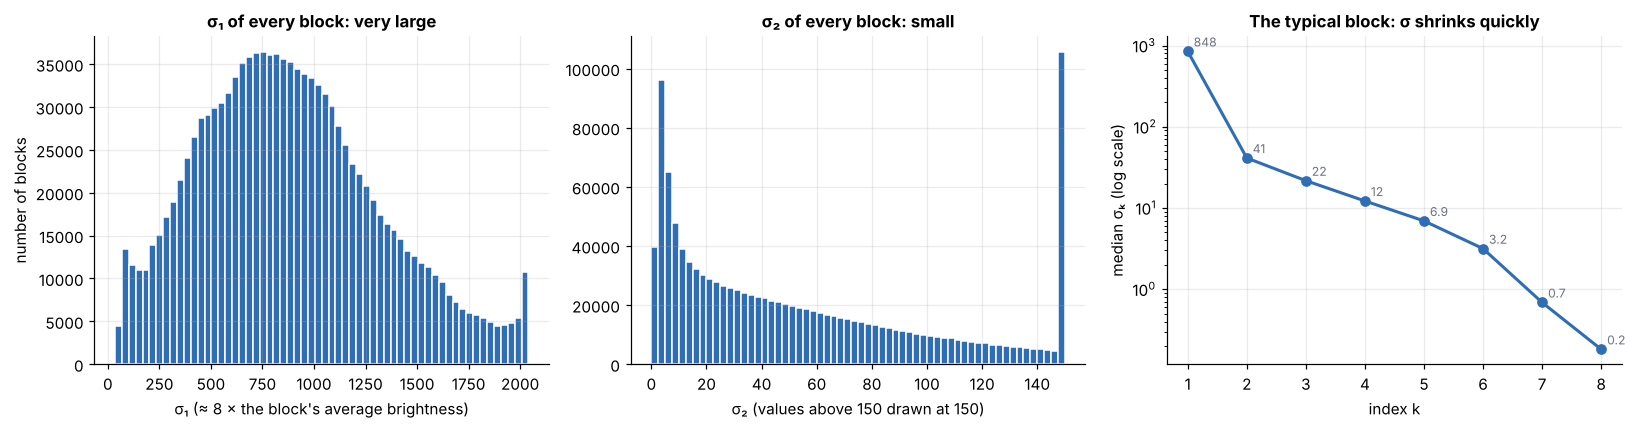

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(S[:, 0], bins=60, color=BLUE, edgecolor="white")
ax[0].set_title("σ₁ of every block: very large"); ax[0].set_xlabel("σ₁ (≈ 8 × the block's average brightness)"); ax[0].set_ylabel("number of blocks")
clip = 150
ax[1].hist(np.clip(S[:, 1], 0, clip), bins=60, color=BLUE, edgecolor="white")
ax[1].set_title("σ₂ of every block: small"); ax[1].set_xlabel(f"σ₂ (values above {clip} drawn at {clip})")
ax[2].semilogy(range(1, 9), np.median(S, axis=0), "o-", color=BLUE, lw=2)
for i, v in enumerate(np.median(S, axis=0)): ax[2].text(i + 1.1, v * 1.15, f"{v:,.0f}" if v >= 10 else f"{v:.1f}", fontsize=8, color=GRAY)
ax[2].set_title("The typical block: σ shrinks quickly"); ax[2].set_xlabel("index k"); ax[2].set_ylabel("median σₖ (log scale)")
plt.tight_layout(); plt.show()

In [18]:
rows = []
for d in (2, 4, 8, 16, 32):
    rows.append({"Step size Δ": d,
                 "Pixel change in the block (RMS, ≤ Δ/8)": d / 8,
                 "Blocks where σ₂ < Δ (%)": (S[:, 1] < d).mean() * 100,
                 "Blocks where σ₃ < Δ (%)": (S[:, 2] < d).mean() * 100})
delta_tbl = pd.DataFrame(rows).set_index("Step size Δ")
display(Markdown("**Candidate step sizes Δ** (RMS = typical size of the pixel change inside the block, ignoring extra rounding to whole gray levels; σ can move by up to Δ)"))
display(delta_tbl)

**Candidate step sizes Δ** (RMS = typical size of the pixel change inside the block, ignoring extra rounding to whole gray levels; σ can move by up to Δ)

,"Pixel change in the block (RMS, ≤ Δ/8)",Blocks where σ₂ < Δ (%),Blocks where σ₃ < Δ (%)
Step size Δ,,,
2,0.2,2.2,7.3
4,0.5,8.3,17.3
8,1.0,17.6,28.3
16,2.0,28.0,42.2
32,4.0,42.8,61.6


In [19]:
med = np.median(S, axis=0)
display(Markdown(f"""**Takeaway.**
* σ₁ is huge (median **{med[0]:,.0f}**) because it mostly encodes the block's average brightness; σ₂ is only **{med[1]:,.0f}** and σ₃ **{med[2]:,.0f}**; by σ₈ it is **{med[7]:.1f}**.
  Outside σ₁ a block keeps only {np.median(1 - S[:,0]**2/(S**2).sum(axis=1))*100:.2f}% (median) of its energy.
* For the same Δ the pixel change has the same size (at most Δ/8 gray levels RMS) **whichever σ is chosen**. The choice changes the *kind* of change: σ₁ shifts the whole block's brightness, later σ add or remove fine texture.
* What differs is whether σ is large enough to carry steps of size Δ. Later σ are small: with Δ = 8, **{delta_tbl.loc[8, 'Blocks where σ₂ < Δ (%)']:.0f}%** of blocks have σ₂ < Δ, meaning the change could exceed σ₂ itself, so those blocks are unsafe to embed in.
* The pilot experiment (task #7) will pick the actual σₖ and Δ by measuring image quality (PSNR) and bit errors (BER) over this range."""))

**Takeaway.**
* σ₁ is huge (median **848**) because it mostly encodes the block's average brightness; σ₂ is only **41** and σ₃ **22**; by σ₈ it is **0.2**.
  Outside σ₁ a block keeps only 0.47% (median) of its energy.
* For the same Δ the pixel change has the same size (at most Δ/8 gray levels RMS) **whichever σ is chosen**. The choice changes the *kind* of change: σ₁ shifts the whole block's brightness, later σ add or remove fine texture.
* What differs is whether σ is large enough to carry steps of size Δ. Later σ are small: with Δ = 8, **18%** of blocks have σ₂ < Δ, meaning the change could exceed σ₂ itself, so those blocks are unsafe to embed in.
* The pilot experiment (task #7) will pick the actual σₖ and Δ by measuring image quality (PSNR) and bit errors (BER) over this range.

## 7. Save the clean image list and summarise

`results/clean_manifest.csv` lists the images that the main experiment will use, with their statistics.

In [20]:
manifest = clean[["split", "filename", "width", "height", "brightness_mean", "contrast_std", "darkest_px", "brightest_px", "status"]]
manifest.to_csv(ROOT / "results" / "clean_manifest.csv", index=False)
print(f"Saved {len(manifest)} rows -> results/clean_manifest.csv")

summary = pd.DataFrame([
    ["Images before / after cleaning", f"{N} / {kept}", "Cleaning table"],
    ["Images needing a crop to multiples of 8", f"{int(df['needs_crop'].sum())} ({df['needs_crop'].mean()*100:.0f}%)", "Cleaning, preprocessing"],
    ["Standardised matrix sizes", ", ".join(sorted({f'{a.shape[0]}×{a.shape[1]}' for a in imgs.values()})), "Matrix representation"],
    ["Average brightness / contrast", f"{clean['brightness_mean'].mean():.0f} / {clean['contrast_std'].mean():.0f}", "Data statistics"],
    ["Images with a pure-white pixel (clipping risk)", f"{int((clean['brightest_px']==255).sum())} ({(clean['brightest_px']==255).mean()*100:.0f}%)", "Problems / limitations"],
    ["Energy in σ₁ (average image)", f"{e1.mean():.0f}%", "Theory 1: SVD energy"],
    ["Median rank for 95% energy", f"{np.median(kk[95]):.0f} of {full_rank}", "Theory 1: SVD energy"],
    ["Median block σ₁ / σ₂ / σ₃", f"{med[0]:,.0f} / {med[1]:,.0f} / {med[2]:,.0f}", "Choosing Δ (QIM)"],
], columns=["Key number", "Value", "Used in the report for"]).set_index("Key number")
display(Markdown("**Key numbers from this notebook**"))
display(summary)

Saved 500 rows -> results/clean_manifest.csv


**Key numbers from this notebook**

,Value,Used in the report for
Key number,,
Images before / after cleaning,500 / 500,Cleaning table
Images needing a crop to multiples of 8,500 (100%),"Cleaning, preprocessing"
Standardised matrix sizes,"320×480, 480×320",Matrix representation
Average brightness / contrast,109 / 51,Data statistics
Images with a pure-white pixel (clipping risk),207 (41%),Problems / limitations
Energy in σ₁ (average image),89%,Theory 1: SVD energy
Median rank for 95% energy,4 of 320,Theory 1: SVD energy
Median block σ₁ / σ₂ / σ₃,848 / 41 / 22,Choosing Δ (QIM)
